# Projektni zadatak: Analiza podataka za smanjenje ugljičnog otiska RH
## Optimizacija lokacija za solarne i vjetroelektrane

Cilj je povezati **klimatske pokazatelje** (osunčanost + vjetar) s emisijama CO₂ te predložiti lokacije s najvećim potencijalom za obnovljive izvore.

**Ulazni izvori (zadani):**
- meteo.hr – klimatski podaci po postajama (osunčanost je izravno dostupna)
- meteo.hr – opis klime u Hrvatskoj (koristi se za interpretaciju)
- PDF dokument: `obvY9201p50_detaljno.pdf` (dokumentacija karte osnovne brzine vjetra)
- CSV (WDI): `API_EN.GHG.CO2.TR.MT.CE.AR5_DS2_en_csv_v2_174360.csv` (emisije CO₂, sektor transport)

Instalacija potrebnih biblioteka

In [1]:
!pip install -U numpy pandas requests beautifulsoup4 matplotlib scikit-learn geopandas shapely pyproj pyogrio

## Uvoz potrebnih biblioteka
Ovaj kod uvozi sve potrebne biblioteke, dohvaća podatka sa web-a, ima model strojnog učenja (Kmeans i normalizaciju), vizualizaciju i rad sa SQLite bazom, a geopandas i folium pokušava učitati samo ako su instalirani. Postavlja putanju za datoteke te provjerava da su PDF i CSV datoteke postavljene u istom folder kao i .ipynb datoteka.

In [2]:
import os
import json
import sqlite3
from pathlib import Path
from typing import Dict, Tuple, Optional
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import requests
import io
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

try:
    import geopandas as gpd
    from shapely.geometry import Point
except Exception:
    gpd = None
    Point = None

try:
    import folium
    from folium.plugins import MarkerCluster
except Exception:
    folium = None
    MarkerCluster = None


from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 140)

BASE_DIR = Path(".").resolve()
CACHE_DIR = BASE_DIR / "meteo_cache"
CACHE_DIR.mkdir(exist_ok=True)

PDF_PATH = BASE_DIR / "obvY9201p50_detaljno.pdf"
CO2_CSV_PATH = BASE_DIR / "API_EN.GHG.CO2.TR.MT.CE.AR5_DS2_en_csv_v2_174360.csv"
DB_PATH = BASE_DIR / "projekt_hr_energija.sqlite"

print("BASE_DIR:", BASE_DIR)
print("PDF exists:", PDF_PATH.exists())
print("CSV exists:", CO2_CSV_PATH.exists())


BASE_DIR: /content
PDF exists: True
CSV exists: True


## 2. Izvori i odabrane lokacije (meteorološke postaje)

Za klimatske podatke s meteo.hr koristimo URL oblik:

`https://meteo.hr/klima.php?section=klima_podaci&param=k1&Grad=<slug>`

Primjer: `Grad=zagreb_gric`.

U nastavku definiramo skup reprezentativnih lokacija (postaja) širom RH te njihove približne geografske koordinate (za kartu).


In [3]:

LOKACIJE: Dict[str, Dict[str, object]] = {
    "Bjelovar": {"slug": "bjelovar", "lat": 45.90, "lon": 16.84, "zona": "inland"},
    "Dubrovnik": {"slug": "dubrovnik", "lat": 42.65, "lon": 18.09, "zona": "coast"},
    "Gospić": {"slug": "gospic", "lat": 44.55, "lon": 15.37, "zona": "inland"},
    "Hvar": {"slug": "hvar", "lat": 43.17, "lon": 16.44, "zona": "island"},
    "Karlovac": {"slug": "karlovac", "lat": 45.49, "lon": 15.55, "zona": "inland"},
    "Knin": {"slug": "knin", "lat": 44.04, "lon": 16.20, "zona": "inland"},
    "Križevci": {"slug": "krizevci", "lat": 46.02, "lon": 16.54, "zona": "inland"},
    "Mali Lošinj": {"slug": "mali_losinj", "lat": 44.53, "lon": 14.47, "zona": "island"},
    "Ogulin": {"slug": "ogulin", "lat": 45.27, "lon": 15.23, "zona": "mountain"},
    "Osijek": {"slug": "osijek", "lat": 45.56, "lon": 18.68, "zona": "inland"},
    "Parg": {"slug": "parg", "lat": 45.38, "lon": 14.78, "zona": "mountain"},
    "Pazin": {"slug": "pazin", "lat": 45.24, "lon": 13.94, "zona": "inland"},
    "Rijeka": {"slug": "rijeka", "lat": 45.33, "lon": 14.44, "zona": "coast"},
    "Senj": {"slug": "senj", "lat": 44.99, "lon": 14.90, "zona": "coast_high_wind"},
    "Sisak": {"slug": "sisak", "lat": 45.49, "lon": 16.37, "zona": "inland"},
    "Slavonski Brod": {"slug": "slavonski_brod", "lat": 45.16, "lon": 18.01, "zona": "inland"},
    "Split-Marjan": {"slug": "split_marjan", "lat": 43.51, "lon": 16.43, "zona": "coast"},
    "Šibenik": {"slug": "sibenik", "lat": 43.74, "lon": 15.89, "zona": "coast"},
    "Varaždin": {"slug": "varazdin", "lat": 46.31, "lon": 16.34, "zona": "inland"},
    "Zadar": {"slug": "zadar", "lat": 44.12, "lon": 15.23, "zona": "coast_high_wind"},
    "Zagreb-Grič": {"slug": "zagreb_gric", "lat": 45.81, "lon": 15.97, "zona": "inland"},
    "Zagreb-Maksimir": {"slug": "zagreb_maksimir", "lat": 45.83, "lon": 16.02, "zona": "inland"},
    "Zavižan": {"slug": "zavizan", "lat": 44.82, "lon": 14.99, "zona": "mountain_high_wind"},
}

print("Broj lokacija:", len(LOKACIJE))
list(LOKACIJE.items())[:3]


Broj lokacija: 23


[('Bjelovar',
  {'slug': 'bjelovar', 'lat': 45.9, 'lon': 16.84, 'zona': 'inland'}),
 ('Dubrovnik',
  {'slug': 'dubrovnik', 'lat': 42.65, 'lon': 18.09, 'zona': 'coast'}),
 ('Gospić', {'slug': 'gospic', 'lat': 44.55, 'lon': 15.37, 'zona': 'inland'})]

## 3. Prikupljanje klimatskih podataka s meteo.hr

### 3.1 Osunčanost (trajanje sijanja Sunca)

Na stranici meteo.hr za svaku lokaciju postoji tablica TRAJANJE OSUNČAVANJA s retkom Suma [sati]. Kada zbrojimo svih 12 mjeseci dobivamo procjenu sati u godini.

U kodu koristimo `requests` za dohvat HTML-a, spremamo HTML u `meteo_cache/` (da se izbjegne ponovno preuzimanje), parsiramo tablice pomoću `pandas.read_html` (fallback na BeautifulSoup ako treba).


In [4]:
def download_with_cache(url: str, cache_path: Path, timeout: int = 30) -> str:
    """Preuzmi URL i spremi u cache. Ako je cache datoteka već tu, koristi nju."""
    if cache_path.exists():
        return cache_path.read_text(encoding="utf-8", errors="ignore")

    try:
        resp = requests.get(url, timeout=timeout, headers={"User-Agent": "Mozilla/5.0"})
        resp.raise_for_status()
        cache_path.write_text(resp.text, encoding="utf-8")
        return resp.text
    except Exception as e:
        if cache_path.exists():
            return cache_path.read_text(encoding="utf-8", errors="ignore")
        raise RuntimeError(f"Ne mogu dohvatiti URL: {url}. Greška: {e}")


def parse_godisnji_suncani_sati(html: str) -> Optional[float]:
    """Vrati godišnji broj sunčanih sati (zbroj mjesečnih 'Suma [sati]')."""
    try:
        tables = pd.read_html(io.StringIO(html))
    except Exception:
        tables = []

    month_cols_hr = [
        "siječanj", "veljača", "ožujak", "travanj", "svibanj", "lipanj",
        "srpanj", "kolovoz", "rujan", "listopad", "studeni", "prosinac"
    ]

    for df in tables:
        cols_lower = [str(c).strip().lower() for c in df.columns]
        if any(m in cols_lower for m in month_cols_hr):
            first_col = df.columns[0]
            s = df[first_col].astype(str).str.lower()
            hit = df[s.str.contains("suma") & s.str.contains("sati")]
            if not hit.empty:
                row = hit.iloc[0]
                vals = []
                for m in month_cols_hr:
                    for c in df.columns:
                        if str(c).strip().lower() == m:
                            v = row[c]
                            vals.append(v)
                            break
                if len(vals) >= 10:
                    nums = pd.to_numeric(pd.Series(vals).astype(str).str.replace(",", "."), errors="coerce")
                    total = float(np.nansum(nums.values))
                    if np.isfinite(total) and total > 0:
                        return total

    soup = BeautifulSoup(html, "html.parser")
    text = soup.get_text(" ")
    if "Trajanje osunčavanja" not in text and "TRAJANJE OSUNČAVANJA" not in text:
        return None

    return None


def dohvat_osuncanosti_po_postaji(naziv: str, slug: str) -> float:
    """Preuzmi meteo.hr stranicu i izvuci godišnje sunčane sate."""
    url = f"https://meteo.hr/klima.php?section=klima_podaci&param=k1&Grad={slug}"
    cache_path = CACHE_DIR / f"meteo_{slug}.html"
    html = download_with_cache(url, cache_path)
    total = parse_godisnji_suncani_sati(html)

    if total is None:
        return float("nan")

    return total


records = []
for naziv, info in LOKACIJE.items():
    slug = info["slug"]
    try:
        sun_hours = dohvat_osuncanosti_po_postaji(naziv, slug)
    except Exception as e:
        print(f"[UPOZORENJE] {naziv}: neuspješan dohvat osunčanosti -> {e}")
        sun_hours = float("nan")

    records.append({
        "lokacija": naziv,
        "slug": slug,
        "lat": float(info["lat"]),
        "lon": float(info["lon"]),
        "zona": info["zona"],
        "sun_sati_god": sun_hours,
    })

klima_df = pd.DataFrame(records)

print("Lokacije s NaN za osunčanost (ako ih ima):")
print(klima_df[klima_df["sun_sati_god"].isna() | ~np.isfinite(klima_df["sun_sati_god"])][["lokacija", "slug", "sun_sati_god"]])

klima_df.sort_values("sun_sati_god", ascending=False).head(10)


Lokacije s NaN za osunčanost (ako ih ima):
Empty DataFrame
Columns: [lokacija, slug, sun_sati_god]
Index: []


,lokacija,slug,lat,lon,zona,sun_sati_god
3,Hvar,hvar,43.17,16.44,island,2752.8
17,Šibenik,sibenik,43.74,15.89,coast,2692.9
16,Split-Marjan,split_marjan,43.51,16.43,coast,2644.8
1,Dubrovnik,dubrovnik,42.65,18.09,coast,2641.0
7,Mali Lošinj,mali_losinj,44.53,14.47,island,2624.4
19,Zadar,zadar,44.12,15.23,coast_high_wind,2590.8
5,Knin,knin,44.04,16.20,inland,2437.6
11,Pazin,pazin,45.24,13.94,inland,2326.7
13,Senj,senj,44.99,14.90,coast_high_wind,2273.0
12,Rijeka,rijeka,45.33,14.44,coast,2218.3


### 3.2 Vjetar (brzina vjetra)

Ovaj dio koda dodjeljuje svakoj lokaciji procijenjenu brzinu vjetra (vjetar_ms) na temelju kategorije zone koristeći rječnik WIND_ZONE_SPEED. Ako neka zona nema definiranu vrijednost ,dobije NaN, tada se ta vrijednost popunjava medijanom svih dostupnih brzina vjetra kako analiza ne bi pukla. Na kraju se ispisuje top 10 lokacija s najvećim procijenjenim vjetrom zajedno sa zonom i sunčanim satima.


In [5]:

WIND_ZONE_SPEED = {
    "inland": 4.5,
    "coast": 6.5,
    "island": 6.8,
    "coast_high_wind": 7.8,
    "mountain": 6.0,
    "mountain_high_wind": 8.2,
}

klima_df["vjetar_ms"] = klima_df["zona"].map(WIND_ZONE_SPEED).astype(float)

median_wind = float(np.nanmedian(klima_df["vjetar_ms"]))
klima_df["vjetar_ms"] = klima_df["vjetar_ms"].fillna(median_wind)

klima_df[["lokacija", "zona", "sun_sati_god", "vjetar_ms"]].sort_values("vjetar_ms", ascending=False).head(10)


,lokacija,zona,sun_sati_god,vjetar_ms
22,Zavižan,mountain_high_wind,2063.2,8.2
13,Senj,coast_high_wind,2273.0,7.8
19,Zadar,coast_high_wind,2590.8,7.8
7,Mali Lošinj,island,2624.4,6.8
3,Hvar,island,2752.8,6.8
1,Dubrovnik,coast,2641.0,6.5
17,Šibenik,coast,2692.9,6.5
12,Rijeka,coast,2218.3,6.5
16,Split-Marjan,coast,2644.8,6.5
10,Parg,mountain,1759.4,6.0


## 4. Emisije CO₂ (WDI CSV + pokušaj preko World Bank API-ja)

U zadanoj CSV datoteci se nalazi WDI indikator: EN.GHG.CO2.TR.MT.CE.AR5 (emisije CO₂ iz sektora transporta, u Mt CO₂e).

Po uputi dodatno pokušavamo dohvatiti još jedan WDI indikator preko API-ja – najčešće korišten je ukupne CO₂ emisije EN.ATM.CO2E.KT (u kilotonama). Ako API ne radi, nastavljamo dalje samo s CSV-om.

In [6]:
def ucitaj_wdi_csv(path: Path, country_code: str = "HRV") -> pd.DataFrame:
    """Učitaj World Bank CSV export i vrati long-format tablicu za odabranu državu."""
    df = pd.read_csv(path, skiprows=4)
    df = df[df["Country Code"] == country_code].copy()
    if df.empty:
        raise ValueError(f"Nema podataka za country_code={country_code} u {path.name}")

    id_cols = ["Country Name", "Country Code", "Indicator Name", "Indicator Code"]
    year_cols = [c for c in df.columns if c.isdigit()]

    long_df = df.melt(id_vars=id_cols, value_vars=year_cols, var_name="godina", value_name="emisija")
    long_df["godina"] = long_df["godina"].astype(int)
    long_df["emisija"] = pd.to_numeric(long_df["emisija"], errors="coerce")
    long_df = long_df.dropna(subset=["emisija"])

    long_df = long_df.rename(columns={
        "Indicator Name": "sektor",
        "Indicator Code": "indikator"
    })
    long_df["jedinica"] = "Mt CO2e"
    long_df["izvor"] = "WDI CSV"

    return long_df[["godina", "emisija", "sektor", "indikator", "jedinica", "izvor"]]


def fetch_wdi_indicator_api(country_code: str, indicator: str, per_page: int = 20000) -> pd.DataFrame:
    """Dohvati WDI indikator preko World Bank API-ja (JSON)."""
    url = f"https://api.worldbank.org/v2/country/{country_code}/indicator/{indicator}?format=json&per_page={per_page}"
    resp = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
    resp.raise_for_status()
    data = resp.json()
    if not isinstance(data, list) or len(data) < 2:
        raise ValueError("Neočekivan JSON format")

    rows = []
    for r in data[1]:
        year = r.get("date")
        value = r.get("value")
        if year is None:
            continue
        if value is None:
            continue
        rows.append({
            "godina": int(year),
            "emisija": float(value),
            "sektor": r.get("indicator", {}).get("value", indicator),
            "indikator": r.get("indicator", {}).get("id", indicator),
            "jedinica": "(ovisno o indikatoru)",
            "izvor": "WDI API",
        })

    out = pd.DataFrame(rows).sort_values("godina")
    return out

co2_transport_df = ucitaj_wdi_csv(CO2_CSV_PATH, country_code="HRV")
print("Transport (CSV) – godine:", co2_transport_df["godina"].min(), "-", co2_transport_df["godina"].max())
co2_transport_df.tail(5)


Transport (CSV) – godine: 1970 - 2024


,godina,emisija,sektor,indikator,jedinica,izvor
60,2020,5.7055,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
61,2021,6.1622,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
62,2022,6.6454,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
63,2023,7.4837,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
64,2024,8.0351,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV


In [7]:
api_df = None
try:
    api_raw = fetch_wdi_indicator_api("HRV", "EN.ATM.CO2E.KT")
    api_df = api_raw.copy()

    api_df["emisija"] = api_df["emisija"] / 1000.0
    api_df["jedinica"] = "Mt CO2"
    api_df["sektor"] = "Ukupne CO2 emisije (pretv.)"
    print("API uspjeh – godine:", api_df["godina"].min(), "-", api_df["godina"].max())
except Exception as e:
    print("[INFO] WDI API nije dostupan ili je došlo do greške:", e)
    print("Nastavljam s Opcijom 1 (samo CSV).")

api_df.tail(5) if api_df is not None else "(API nije korišten)"


[INFO] WDI API nije dostupan ili je došlo do greške: Neočekivan JSON format
Nastavljam s Opcijom 1 (samo CSV).


'(API nije korišten)'

In [8]:
ugljik_df = co2_transport_df.copy()
if api_df is not None and not api_df.empty:
    ugljik_df = pd.concat([ugljik_df, api_df], ignore_index=True)

ugljik_df = ugljik_df.sort_values(["sektor", "godina"]).reset_index(drop=True)
ugljik_df.head(10)


,godina,emisija,sektor,indikator,jedinica,izvor
0,1970,4.1313,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
1,1971,4.1313,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
2,1972,3.5968,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
3,1973,3.4486,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
4,1974,3.5721,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
5,1975,3.3535,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
6,1976,3.3171,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
7,1977,3.2948,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
8,1978,3.6580,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV
9,1979,3.5205,Carbon dioxide (CO2) emissions from Transport ...,EN.GHG.CO2.TR.MT.CE.AR5,Mt CO2e,WDI CSV


## 5. Integracija i analiza: rangiranje lokacija + jednostavan ML

Ovaj blok prvo provjerava da u klima_df postoji stupac sun_sati_god, pretvara ga u brojčani tip i zamjenjuje nevaljane vrijednosti (inf/NaN) medijanom kako bi podaci bili “čisti” za daljnju analizu. Zatim osigurava da postoji vjetar_ms (ako ga nema, pokušava ga izračunati iz zona mapiranjem na tipične brzine vjetra) te i njega čisti i popunjava medijanom. Nakon toga normalizira sun_sati_god i vjetar_ms u raspon 0–1 (MinMaxScaler), računa score-ove za solarni i vjetro potencijal te ukupni score, grupira lokacije u do 3 klastera (KMeans) i na kraju ispisuje top lokacije za solar, vjetar i kombinirani potencijal.

In [9]:
if "sun_sati_god" not in klima_df.columns:
    raise KeyError("Nedostaje stupac 'sun_sati_god'. Provjeri blok dohvat/parsiranja osunčanosti.")

klima_df["sun_sati_god"] = pd.to_numeric(klima_df["sun_sati_god"], errors="coerce")
klima_df["sun_sati_god"] = klima_df["sun_sati_god"].replace([np.inf, -np.inf], np.nan)

median_sun = float(np.nanmedian(klima_df["sun_sati_god"].values))
if not np.isfinite(median_sun):
    raise ValueError("Ne mogu izračunati median sunčanih sati (sve vrijednosti su NaN). Provjeri parsing meteo tablica.")

klima_df["sun_sati_god"] = klima_df["sun_sati_god"].fillna(median_sun)
if "vjetar_ms" not in klima_df.columns:

    if "zona" not in klima_df.columns:
        raise KeyError("Nedostaje 'vjetar_ms' i 'zona'. Dodaj zonu u LOKACIJE ili ranije kreiraj vjetar_ms.")


    zona_u_vjetar = {
        "kontinentalna": 3.0,
        "gorska": 5.0,
        "priobalna": 6.5,
        "otoci": 7.5,
        "velebit": 9.0
    }

    klima_df["vjetar_ms"] = klima_df["zona"].astype(str).str.lower().map(zona_u_vjetar)

klima_df["vjetar_ms"] = pd.to_numeric(klima_df["vjetar_ms"], errors="coerce").replace([np.inf, -np.inf], np.nan)
median_wind = float(np.nanmedian(klima_df["vjetar_ms"].values))
if not np.isfinite(median_wind):

    median_wind = 5.0
klima_df["vjetar_ms"] = klima_df["vjetar_ms"].fillna(median_wind)


from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

scaler = MinMaxScaler()
klima_df[["sun_norm", "wind_norm"]] = scaler.fit_transform(klima_df[["sun_sati_god", "vjetar_ms"]])

klima_df["solar_score"] = klima_df["sun_norm"]
klima_df["wind_score"] = klima_df["wind_norm"]
klima_df["combined_score"] = 0.5 * klima_df["solar_score"] + 0.5 * klima_df["wind_score"]

X = klima_df[["sun_norm", "wind_norm"]].values

n_clusters = min(3, len(klima_df))
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
klima_df["cluster"] = kmeans.fit_predict(X)

TOP_N = 5
najbolje_solar = klima_df.sort_values("solar_score", ascending=False).head(TOP_N)
najbolje_wind = klima_df.sort_values("wind_score", ascending=False).head(TOP_N)

print("Top solar lokacije:")
display(najbolje_solar[["lokacija", "sun_sati_god", "solar_score", "vjetar_ms", "cluster"]])

print("Top wind lokacije:")
display(najbolje_wind[["lokacija", "vjetar_ms", "wind_score", "sun_sati_god", "cluster"]])

print("Top kombinirane lokacije:")
display(klima_df.sort_values("combined_score", ascending=False).head(10)[["lokacija", "sun_sati_god", "vjetar_ms", "combined_score", "cluster"]])


Top solar lokacije:


,lokacija,sun_sati_god,solar_score,vjetar_ms,cluster
3,Hvar,2752.8,1.000000,6.8,1
17,Šibenik,2692.9,0.939702,6.5,1
16,Split-Marjan,2644.8,0.891282,6.5,1
1,Dubrovnik,2641.0,0.887457,6.5,1
7,Mali Lošinj,2624.4,0.870747,6.8,1


Top wind lokacije:


,lokacija,vjetar_ms,wind_score,sun_sati_god,cluster
22,Zavižan,8.2,1.000000,2063.2,0
13,Senj,7.8,0.891892,2273.0,1
19,Zadar,7.8,0.891892,2590.8,1
7,Mali Lošinj,6.8,0.621622,2624.4,1
3,Hvar,6.8,0.621622,2752.8,1


Top kombinirane lokacije:


,lokacija,sun_sati_god,vjetar_ms,combined_score,cluster
19,Zadar,2590.8,7.8,0.864408,1
3,Hvar,2752.8,6.8,0.810811,1
7,Mali Lošinj,2624.4,6.8,0.746184,1
17,Šibenik,2692.9,6.5,0.740121,1
16,Split-Marjan,2644.8,6.5,0.715912,1
1,Dubrovnik,2641.0,6.5,0.713999,1
13,Senj,2273.0,7.8,0.704452,1
22,Zavižan,2063.2,8.2,0.652909,0
12,Rijeka,2218.3,6.5,0.501245,0
5,Knin,2437.6,4.5,0.341353,2


## 6. Procjena smanjenja emisija ako se elektrane postave na sve identificirane lokacije

Ovaj blok procjenjuje koliko bi se emisija CO2 smanjila kada bi se vjetroelektrane postavile na N mjesta. Zatim računa godišnju proizvodnju u MWh za svaku lokaciju i pretvara je u izbjegnute emisije CO2 koristeći emisijski faktor, pa na kraju ispisuje ukupno izbjegnute emisije i rangira lokacije po najvećem doprinosu. Uz to ima provjeru da su se prijašnje radnje izvršile.

In [10]:
SOLAR_MW_PER_SITE = 50
WIND_MW_PER_SITE  = 100

EMISSION_FACTOR_TCO2_PER_MWH = 0.4

HOURS_YEAR = 8760
TOP_N = 5

required_cols = ["sun_norm", "wind_norm", "solar_score", "wind_score", "lokacija"]
missing = [c for c in required_cols if c not in klima_df.columns]
if missing:
    raise KeyError(f"Nedostaju stupci {missing}. Pokreni prethodni blok (normalizacija/skoring) prije ovog.")

klima_df["cf_solar"] = 0.10 + 0.12 * klima_df["sun_norm"]
klima_df["cf_wind"] = 0.20 + 0.20 * klima_df["wind_norm"]
klima_df["cf_solar"] = klima_df["cf_solar"].clip(0, 1)
klima_df["cf_wind"]  = klima_df["cf_wind"].clip(0, 1)

solar_sites = klima_df.sort_values("solar_score", ascending=False).head(TOP_N).copy()
wind_sites  = klima_df.sort_values("wind_score", ascending=False).head(TOP_N).copy()

solar_sites["kapacitet_mw"] = SOLAR_MW_PER_SITE
solar_sites["cf"] = solar_sites["cf_solar"]
solar_sites["tip"] = "solar"

wind_sites["kapacitet_mw"] = WIND_MW_PER_SITE
wind_sites["cf"] = wind_sites["cf_wind"]
wind_sites["tip"] = "wind"

sites = pd.concat([solar_sites, wind_sites], ignore_index=True)
sites["proizvodnja_mwh"] = sites["kapacitet_mw"] * HOURS_YEAR * sites["cf"]
sites["izbjegnute_tco2"] = sites["proizvodnja_mwh"] * EMISSION_FACTOR_TCO2_PER_MWH
sites["izbjegnute_mtco2"] = sites["izbjegnute_tco2"] / 1e6

ukupno_izbjegnute_mt = float(sites["izbjegnute_mtco2"].sum())

print("Procjena izbjegnutih emisija (Mt CO2 godišnje):", round(ukupno_izbjegnute_mt, 3))

sites[["lokacija", "tip", "kapacitet_mw", "cf", "proizvodnja_mwh", "izbjegnute_mtco2"]].sort_values(
    "izbjegnute_mtco2", ascending=False
)

Procjena izbjegnutih emisija (Mt CO2 godišnje): 0.817


,lokacija,tip,kapacitet_mw,cf,proizvodnja_mwh,izbjegnute_mtco2
5,Zavižan,wind,100,0.400000,350400.000000,0.140160
6,Senj,wind,100,0.378378,331459.459459,0.132584
7,Zadar,wind,100,0.378378,331459.459459,0.132584
8,Mali Lošinj,wind,100,0.324324,284108.108108,0.113643
9,Hvar,wind,100,0.324324,284108.108108,0.113643
0,Hvar,solar,50,0.220000,96360.000000,0.038544
1,Šibenik,solar,50,0.212764,93190.738877,0.037276
2,Split-Marjan,solar,50,0.206954,90645.806322,0.036258
3,Dubrovnik,solar,50,0.206495,90444.751359,0.036178
4,Mali Lošinj,solar,50,0.204490,89566.458627,0.035827


Ovaj dio koda prvo određuje baseline emisija s kojim će usporediti procjenu smanjenja. Te ispod ispisuje procijenjeno smanjenje CO2 godišnje, te koliki je to udio u baseline-u

In [11]:
baseline = None
baseline_label = None

if api_df is not None and not api_df.empty:
    last_year = int(api_df["godina"].max())
    baseline = float(api_df.loc[api_df["godina"] == last_year, "emisija"].iloc[0])
    baseline_label = f"Ukupne CO2 emisije (API) {last_year}"
else:
    last_year = int(co2_transport_df["godina"].max())
    baseline = float(co2_transport_df.loc[co2_transport_df["godina"] == last_year, "emisija"].iloc[0])
    baseline_label = f"Transport CO2 (CSV) {last_year}"

postotak = 100.0 * ukupno_izbjegnute_mt / baseline if baseline and baseline > 0 else float("nan")

print("Baseline:", baseline_label, "=", baseline, ("Mt"))
print("Procijenjeno smanjenje:", round(ukupno_izbjegnute_mt, 3), "Mt CO2/god")
print("Udio u baseline:", round(postotak, 2), "%")


Baseline: Transport CO2 (CSV) 2024 = 8.0351 Mt
Procijenjeno smanjenje: 0.817 Mt CO2/god
Udio u baseline: 10.16 %


## 7. Izrada SQLite baze podataka

Kreiramo bazu s dvije tablice:
- klima: lokacija, osunčanost, vjetar, skorovi, koordinate
- ugljik: godina, emisija, sektor, jedinica, izvor

In [12]:
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

cur.execute("DROP TABLE IF EXISTS klima")
cur.execute("DROP TABLE IF EXISTS ugljik")
cur.execute("""
CREATE TABLE klima (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    lokacija TEXT,
    grad_slug TEXT,
    lat REAL,
    lon REAL,
    zona TEXT,
    sun_sati_god REAL,
    vjetar_ms REAL,
    solar_score REAL,
    wind_score REAL,
    combined_score REAL,
    cluster INTEGER
)
""")

cur.execute("""
CREATE TABLE ugljik (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    godina INTEGER,
    emisija REAL,
    sektor TEXT,
    indikator TEXT,
    jedinica TEXT,
    izvor TEXT
)
""")

klima_cols = [
    "lokacija", "slug", "lat", "lon", "zona", "sun_sati_god", "vjetar_ms",
    "solar_score", "wind_score", "combined_score", "cluster"
]

klima_to_insert = klima_df[klima_cols].copy()
klima_to_insert = klima_to_insert.rename(columns={"slug": "grad_slug"})

klima_to_insert.to_sql("klima", conn, if_exists="append", index=False)
ugljik_df.to_sql("ugljik", conn, if_exists="append", index=False)

conn.commit()

print("Rows klima:", cur.execute("SELECT COUNT(*) FROM klima").fetchone()[0])
print("Rows ugljik:", cur.execute("SELECT COUNT(*) FROM ugljik").fetchone()[0])

pd.read_sql_query("SELECT * FROM klima ORDER BY combined_score DESC LIMIT 5", conn)


Rows klima: 23
Rows ugljik: 55


,id,lokacija,grad_slug,lat,lon,zona,sun_sati_god,vjetar_ms,solar_score,wind_score,combined_score,cluster
0,20,Zadar,zadar,44.12,15.23,coast_high_wind,2590.8,7.8,0.836924,0.891892,0.864408,1
1,4,Hvar,hvar,43.17,16.44,island,2752.8,6.8,1.000000,0.621622,0.810811,1
2,8,Mali Lošinj,mali_losinj,44.53,14.47,island,2624.4,6.8,0.870747,0.621622,0.746184,1
3,18,Šibenik,sibenik,43.74,15.89,coast,2692.9,6.5,0.939702,0.540541,0.740121,1
4,17,Split-Marjan,split_marjan,43.51,16.43,coast,2644.8,6.5,0.891282,0.540541,0.715912,1


## 8. Vizualizacija


Stvaramo vizualnu reprezentaciju/kartu na kojoj se nalaze mjesta sa najvećim potencijalom (tj. najboljim score-om vjetra) te ih označimo kao potencijalna mjesta na kojima bi se mogla izgraditi vjetroelektrane i smanjiti emisije CO2.

In [13]:
import geopandas as gpd
from shapely.geometry import Point

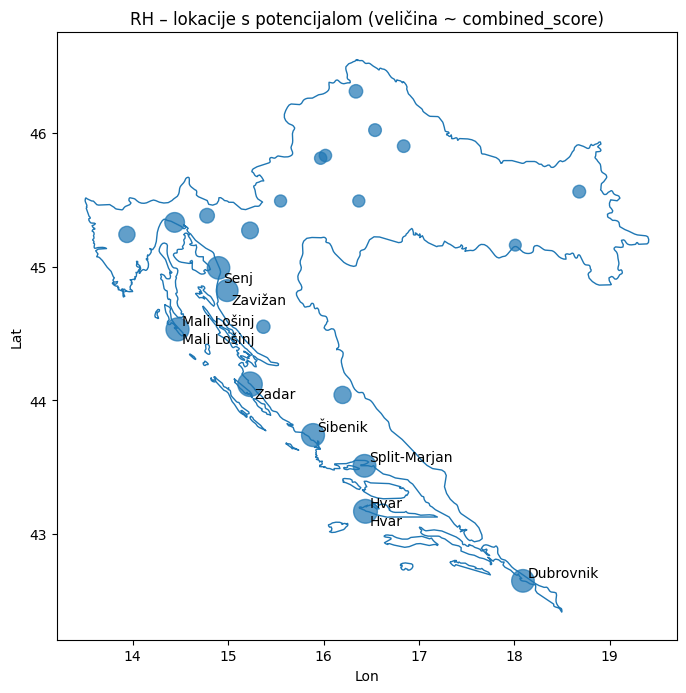

In [14]:
if gpd is None or Point is None:
    print("GeoPandas nije dostupan. Preskačem geo vizualizaciju s granicama.")
else:
    WORLD_GEOJSON = "https://raw.githubusercontent.com/datasets/geo-countries/master/data/countries.geojson"

    world = gpd.read_file(WORLD_GEOJSON).to_crs(epsg=4326)

    name_col = "ADMIN" if "ADMIN" in world.columns else ("name" if "name" in world.columns else None)
    if name_col is None:
        raise KeyError(f"Ne mogu pronaći stupac s nazivom države. Stupci: {list(world.columns)}")

    cro = world[world[name_col].astype(str).str.lower() == "croatia"]

    if cro.empty:
        raise ValueError("Nisam našao 'Croatia' u datasetu granica. Provjeri naziv stupca i vrijednosti.")

    gdf = gpd.GeoDataFrame(
        klima_df.copy(),
        geometry=[Point(xy) for xy in zip(klima_df["lon"], klima_df["lat"])],
        crs="EPSG:4326"
    )

    fig, ax = plt.subplots(figsize=(8, 8))
    cro.boundary.plot(ax=ax, linewidth=1)

    sizes = 50 + 300 * gdf["combined_score"].values

    gdf.plot(
        ax=ax,
        markersize=sizes,
        alpha=0.7
    )
    if "najbolje_solar" in globals():
        for _, row in najbolje_solar.iterrows():
            ax.annotate(row["lokacija"], (row["lon"], row["lat"]), xytext=(3, 3), textcoords="offset points")

    if "najbolje_wind" in globals():
        for _, row in najbolje_wind.iterrows():
            ax.annotate(row["lokacija"], (row["lon"], row["lat"]), xytext=(3, -10), textcoords="offset points")

    ax.set_title("RH – lokacije s potencijalom (veličina ~ combined_score)")
    ax.set_xlabel("Lon")
    ax.set_ylabel("Lat")
    plt.show()

## 8. Zaključci

U ovom projektu sam automatski prikupio potrebne podatke sa web stranica i iz pdf-ova, integrirao potrebne podatke o vjetru. Nakon toga sam učitao emisije o CO2 i probao ih dohvatiti preko API-ja, potom sam izgradio SQLite bazu sa dvije tablice (klima i ugljik). Lokacije sam rangirao i izračunao procjenjeno smanjenje emisije ukoliko se te elektrane izgrade te sam mjesta (koja imaju potencijal da sagrade vjetroelektrane) označio na karti Hrvatske.